# Ajedrez online — Entrega 2.1: hipótesis durante la partida

La pregunta del proyecto es **qué tan bien se predice el resultado, y cuánto falta para el final, antes de que empiece la partida y a medida que avanza**. El notebook 02 cubre el **antes**, con una fila por partida: perfil del dataset, fugas del rating y cuatro hipótesis sobre lo que se sabe al crear la partida. Este notebook cubre el **durante**, sobre la tabla de cortes: una fila por `(partida, corte)`, con cortes a los 0, 10, 20, 30, 40 y 60 medio-movimientos (plies). Las dos juntas forman el análisis exploratorio de la Entrega 2.

**Qué cambió desde la Entrega 1.** La muestra pasó de 8 jugadores a **100 cuentas** (20 por banda de ELO, seleccionadas desde listas públicas de la PubAPI, con la lista congelada y versionada en `config/`), con hasta 1.000 partidas rated de bullet, blitz y rapid por cuenta. El pipeline suma el horario exacto de cada partida, el torneo, el matchup de apertura con su historial sin fuga y la tabla de cortes. El tidy tiene 35 columnas.

**Qué se predice.** El objetivo principal es `resultado` (Gana Blancas / Empate / Gana Negras), en cada corte. El secundario es `plies_restantes` (regresión). Ambos se miran al final de la partida y no existen como feature: son lo que se quiere predecir.


## 1 · Configuración y carga

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import load_config

config = load_config(PROJECT_ROOT / "config" / "config.yaml")
CUTS = config["live_prediction"]["cortes_ply"]
RESULT_ORDER = ["Gana Blancas", "Empate", "Gana Negras"]
TIME_ORDER = ["bullet", "blitz", "rapid"]

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

games = pd.read_parquet(PROJECT_ROOT / config["paths"]["clean_parquet"])
cuts = pd.read_parquet(PROJECT_ROOT / config["paths"]["cortes_parquet"])
print(f"Partidas (tidy): {games.shape[0]:,} × {games.shape[1]} columnas")
print(f"Filas (partida, corte): {cuts.shape[0]:,} × {cuts.shape[1]} columnas")

Partidas (tidy): 80,697 × 35 columnas
Filas (partida, corte): 435,689 × 27 columnas


## 2 · Perfil del dataset

Antes de buscar relaciones se verifica qué contiene la tabla. Una fila de `partidas_cortes` es **una partida vista en un corte**: la posición y los relojes en ese ply, más los dos objetivos. La clave es `(GameUrl, corte_ply)`. El contexto fijo de la partida (ritmo, torneo, matchup) vive en el tidy, cuya clave es `GameUrl`.

In [2]:
print("Tamaño de la tabla de cortes:", cuts.shape)
print("Filas por corte:", cuts["corte_ply"].value_counts().sort_index().to_dict())
print("Partidas distintas:", f"{cuts['GameUrl'].nunique():,}", "· partidas del tidy:", f"{games['GameUrl'].nunique():,}")
print()
print("Tipos de la tabla de cortes:")
display(cuts.dtypes.value_counts().rename("columnas").to_frame())
numeric_as_text = [c for c in cuts.columns if cuts[c].dtype == object and c != "GameUrl"]
print("Columnas de texto distintas de la clave:", numeric_as_text or "ninguna")

Tamaño de la tabla de cortes: (435689, 27)
Filas por corte: {0: 80697, 10: 80099, 20: 78456, 30: 75383, 40: 69788, 60: 51266}
Partidas distintas: 80,697 · partidas del tidy: 80,697

Tipos de la tabla de cortes:


,columnas
int64,11
float64,8
bool,6
str,1
category,1


Columnas de texto distintas de la clave: ninguna


In [3]:
# Nulls: cuts table and tidy table (the tidy holds the structural ones)
nulls_cuts = cuts.isna().mean().sort_values(ascending=False)
nulls_tidy = games.isna().mean().sort_values(ascending=False)
print("Nulos en la tabla de cortes:", int(cuts.isna().sum().sum()))
print("Nulos en el tidy (columnas con al menos uno):")
display(pd.DataFrame({"nulos": games.isna().sum(), "porcentaje": nulls_tidy * 100}).query("nulos > 0"))

# Each null column has a structural explanation: check it, do not assume it
assert games["TournamentUrl"].isna().eq(~games["EsTorneo"]).all(), "TournamentUrl nulo no coincide con EsTorneo"
assert games["tasa_blancas_hist"].isna().eq(~games["historial_suficiente"]).all(), "Tasa nula no coincide con historial insuficiente"
print()
print(f"TournamentUrl nulo = partida que no es de torneo: {games['TournamentUrl'].isna().sum():,} (estructural)")
print(f"tasa_*_hist nulo = menos de 30 partidas previas del matchup: {int((~games['historial_suficiente']).sum()):,} (estructural)")

Nulos en la tabla de cortes: 161394
Nulos en el tidy (columnas con al menos uno):


,nulos,porcentaje
TournamentUrl,74477,92.292
tasa_blancas_hist,1620,2.008
tasa_negras_hist,1620,2.008
tasa_tablas_hist,1620,2.008



TournamentUrl nulo = partida que no es de torneo: 74,477 (estructural)
tasa_*_hist nulo = menos de 30 partidas previas del matchup: 1,620 (estructural)


In [4]:
constants = cuts.columns[cuts.nunique() <= 1].tolist()
print("Columnas constantes en cortes:", constants or "ninguna")
print("Duplicados de la clave (GameUrl, corte_ply):", int(cuts.duplicated(["GameUrl", "corte_ply"]).sum()))
print("Duplicados de GameUrl en el tidy:", int(games["GameUrl"].duplicated().sum()))

Columnas constantes en cortes: ['turno_blancas']
Duplicados de la clave (GameUrl, corte_ply): 0


Duplicados de GameUrl en el tidy: 0


### Distribución del objetivo

`resultado` es la columna objetivo. El número que más importa del perfil es cuánto pesa la clase mayoritaria, porque fija el piso que un modelo tiene que superar. Se muestra por corte y para la población total.

In [5]:
target_by_cut = cuts.groupby("corte_ply")["resultado"].value_counts(normalize=True).unstack().reindex(columns=RESULT_ORDER).mul(100)
target_all = games["resultado"].value_counts(normalize=True).reindex(RESULT_ORDER).mul(100)
display(target_by_cut.round(1))
print("Tidy (todas las partidas):", target_all.round(1).to_dict())
print(f"Clase mayoritaria: {target_all.idxmax()} con {target_all.max():.1f} %")
print("Piso de accuracy sin información (predecir siempre la mayoritaria):", f"{target_all.max():.1f} %")

print()
print("plies_restantes (objetivo secundario) por corte:")
display(cuts.groupby("corte_ply")["plies_restantes"].describe()[["count", "mean", "50%", "max"]])

resultado,Gana Blancas,Empate,Gana Negras
corte_ply,,,
0,49.000,6.100,44.900
10,49.000,6.100,44.900
20,48.900,6.200,44.900
30,48.700,6.400,44.900
40,48.300,6.800,45.000
60,47.200,8.700,44.100


Tidy (todas las partidas): {'Gana Blancas': 49.0, 'Empate': 6.1, 'Gana Negras': 44.9}
Clase mayoritaria: Gana Blancas con 49.0 %
Piso de accuracy sin información (predecir siempre la mayoritaria): 49.0 %

plies_restantes (objetivo secundario) por corte:


,count,mean,50%,max
corte_ply,,,,
0,"80,697.000",75.199,71.000,375.000
10,"80,099.000",65.702,61.000,365.000
20,"78,456.000",56.953,52.000,355.000
30,"75,383.000",49.030,44.000,345.000
40,"69,788.000",42.489,36.000,335.000
60,"51,266.000",33.807,28.000,315.000


In [6]:
skew = cuts.select_dtypes("number").drop(columns=["corte_ply"]).skew().sort_values()
display(skew.round(2).to_frame("asimetria"))
long_tail = skew[skew.abs() > 1].index.tolist()
print("Con cola larga (|asimetría| > 1):", long_tail)

,asimetria
material_no_peon_frac,-1.460
material_negras,-1.430
reloj_frac_blancas,-1.370
material_blancas,-1.360
reloj_frac_negras,-1.330
diferencia_reloj_seg,-0.630
balance_material,-0.550
movilidad,-0.530
plies_restantes,0.760
capturas_negras,1.030


Con cola larga (|asimetría| > 1): ['material_no_peon_frac', 'material_negras', 'reloj_frac_blancas', 'material_blancas', 'reloj_frac_negras', 'capturas_negras', 'capturas_blancas', 'reloj_blancas_seg', 'reloj_negras_seg', 'jaques_blancas', 'jaques_negras', 'gasto_reciente_negras_seg', 'gasto_reciente_blancas_seg', 'promociones']


**Lectura.**

- **Tamaño y unidad.** 435.689 filas × 27 columnas de 80.697 partidas distintas: todas las del tidy, porque todas tienen el corte 0. A partir del corte 10 una partida sólo aparece si sigue en curso en ese ply (80.099 en el corte 10, 51.266 en el 60).
- **Tipos.** Ninguna numérica quedó como texto. Hay 6 booleanas (`en_jaque`, `turno_blancas`, enroques, derechos de enroque) y la clave `GameUrl`.
- **Nulos.** Los 161.394 nulos de la tabla de cortes son `gasto_reciente_blancas_seg` y `gasto_reciente_negras_seg` en las 80.697 filas del corte 0: antes de la primera jugada no hay tiempo gastado que medir. En el tidy sólo hay dos grupos de nulos, los dos **estructurales**: `TournamentUrl` (92,3 %, vacía cuando la partida no es de torneo, verificado contra `EsTorneo`) y `tasa_*_hist` (2,0 %, vacías cuando el matchup tiene menos de 30 partidas previas, verificado contra `historial_suficiente`). No hay faltantes de verdad.
- **Constantes.** `turno_blancas`: todos los cortes caen en plies pares (el 0 incluido), así que siempre mueven blancas. No informa y sale.
- **Duplicados.** 0 en la clave `(GameUrl, corte_ply)` y 0 en `GameUrl` del tidy.
- **Objetivo.** `resultado`: Gana Blancas 49,0 %, Gana Negras 44,9 %, Empate 6,1 %. Ninguna clase se come todo, y el piso sin información es predecir siempre Gana Blancas (49,0 %). El problema es Empate: es minoritaria. Su peso sube a 8,7 % en el ply 60 porque las partidas largas empatan más (sesgo de supervivencia), no porque el empate sea más común.
- **Asimetría.** Cola larga a la derecha en `promociones` (25,7), `gasto_reciente_*_seg` (6,5–7,3), `jaques_*` (4,2–4,3) y `reloj_*_seg` (4,0–4,1); a la izquierda en el material y en `reloj_frac_*` (−1,3 a −1,5), porque en la mayoría de los cortes todavía queda casi todo el material y casi todo el reloj. Como el modelo base es de árboles, no hace falta transformar: sólo `promociones` es candidata a descartarse.


## 3 · Población común y datos de trabajo

Una partida corta no llega al ply 60, así que los cortes tardíos sólo ven partidas largas (sesgo de supervivencia). Comparar el corte 10 con el 60 sobre poblaciones distintas mezclaría "la partida avanzó" con "sólo quedaron las partidas largas". Por eso cada hipótesis se evalúa **sobre la población común**: las partidas que llegan al ply 60 y tienen fila en los cinco cortes con jugadas (10 a 60).

**El corte 0 no entra en estas hipótesis.** En la posición inicial el material y los relojes son iguales para los dos bandos en todas las partidas (`balance_material = 0` y `dif_reloj_frac = 0`, la celda siguiente lo verifica), así que no hay nada que comparar. Lo que se sabe antes de mover lo estudia el notebook 02.

El ritmo (`TimeClass`) se une desde el tidy por `GameUrl` (muchos a uno) con su assert anti fan-out. La diferencia de reloj se expresa como fracción del tiempo base (`reloj_frac_*`), para que sea comparable entre bullet, blitz y rapid.

In [7]:
rows_before = len(cuts)
data = cuts.merge(games[["GameUrl", "TimeClass"]], on="GameUrl", how="left", validate="many_to_one")
assert len(data) == rows_before, "Fan-out detectado al unir el ritmo"
data["TimeClass"] = pd.Categorical(data["TimeClass"].astype(str), categories=TIME_ORDER)
data["dif_reloj_frac"] = data["reloj_frac_blancas"] - data["reloj_frac_negras"]
data["reloj_min_frac"] = data[["reloj_frac_blancas", "reloj_frac_negras"]].min(axis=1)

# Cut 0 is the starting position: material and clocks are equal by construction, so the
# in-game hypotheses are evaluated on the cuts where at least one move was played.
LIVE_CUTS = [k for k in CUTS if k > 0]
max_cut = max(LIVE_CUTS)
common_urls = set(data.loc[data["corte_ply"] == max_cut, "GameUrl"])
common = data[data["GameUrl"].isin(common_urls) & data["corte_ply"].isin(LIVE_CUTS)].copy()
assert common.groupby("GameUrl")["corte_ply"].nunique().eq(len(LIVE_CUTS)).all()
at_zero = data[data["corte_ply"] == 0]
assert (at_zero["balance_material"] == 0).all() and (at_zero["dif_reloj_frac"] == 0).all(), "El corte 0 no es la posición inicial"
print(f"Población común: {len(common_urls):,} partidas ({100 * len(common_urls) / games.shape[0]:.1f} % del total) × {len(LIVE_CUTS)} cortes = {len(common):,} filas")

Población común: 51,266 partidas (63.5 % del total) × 5 cortes = 256,330 filas


## 4 · Método

Metodología de la cátedra: tres formas de afirmación, cada una con su medida (comparación → separación o η²; asociación → Pearson, Spearman y brecha; composición → proporción contra la global) y un semáforo (🔴 débil, 🟡 intermedio, 🟢 fuerte). Cada ficha tiene seis campos: **afirmación, qué espero ver, medida y gráfico, resultado, zona y decisión**, y una etiqueta de pregunta: *Responder* (dominio) o *Predecir* (decide sobre una columna del modelo).

Una hipótesis en 🟡 amarillo no se confirma sin un movimiento que la saque de ahí, y cada ficha admite como máximo dos. Se reporta el valor antes y después.

In [8]:
def eta2(numerica, categoria):
    """Share of numeric variance explained by a categorical grouping (comparación, N grupos)."""
    g = numerica.groupby(categoria, observed=True)
    m = numerica.mean()
    return (g.count() * (g.mean() - m) ** 2).sum() / ((numerica - m) ** 2).sum()


def eta2_controlado(frame, columna, grupo, control):
    """η² of ``columna`` by ``grupo`` with sums of squares pooled inside each ``control`` band."""
    between = total = 0.0
    for _, sub in frame.groupby(control, observed=True):
        valores = sub[columna]
        media = valores.mean()
        total += ((valores - media) ** 2).sum()
        for _, g in sub.groupby(grupo, observed=True):
            between += len(g) * (g[columna].mean() - media) ** 2
    return between / total


def asociacion(x, y):
    """Pearson, Spearman and their gap for two numeric series."""
    p, s = x.corr(y), x.corr(y, method="spearman")
    return pd.Series({"pearson": p, "spearman": s, "brecha": s - p})


CORTES = {"eta2": (0.05, 0.25), "correlacion": (0.2, 0.6), "brecha": (0.05, 0.15)}
ZONA_EMOJI = {"rojo": "🔴", "amarillo": "🟡", "verde": "🟢"}


def semaforo(valor, medida):
    """Zona rojo/amarillo/verde según los cortes definidos en CORTES."""
    bajo, alto = CORTES[medida]
    v = abs(valor)
    return "rojo" if v < bajo else "verde" if v > alto else "amarillo"


def eta2_por_corte(frame, columna):
    return pd.Series({k: eta2(g[columna], g["resultado"]) for k, g in frame.groupby("corte_ply")})


def con_zona(serie, medida):
    tabla = serie.to_frame("valor")
    tabla["zona"] = [ZONA_EMOJI[semaforo(v, medida)] for v in serie]
    return tabla

## 5 · H1′ — Material y resultado, según el corte (*Responder*)

| Campo | Contenido |
|---|---|
| **Afirmación** | El balance de material (`balance_material`, blancas − negras, en puntos clásicos: peón 1, caballo y alfil 3, torre 5, dama 9) difiere entre las partidas que ganaron blancas, empataron y ganaron negras, y esa diferencia **crece con el corte**. |
| **Qué espero ver** | η² cercano a 0 en el ply 10 (casi no hay cambios de material) y creciente hasta el ply 60. |
| **Medida y gráfico** | Comparación (3 grupos): `eta2(balance_material, resultado)` en cada corte, sobre la población común. Gráfico de línea η² contra corte. |

,valor,zona
10,0.000,🔴
20,0.004,🔴
30,0.012,🔴
40,0.033,🔴
60,0.118,🟡


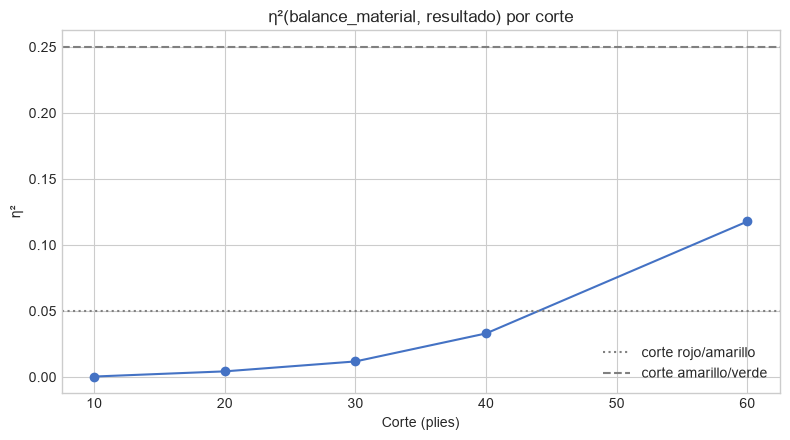

In [9]:
h1 = eta2_por_corte(common, "balance_material")
display(con_zona(h1, "eta2"))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(h1.index, h1.values, marker="o", color="#4472c4")
ax.axhline(0.05, color="gray", linestyle=":", label="corte rojo/amarillo")
ax.axhline(0.25, color="gray", linestyle="--", label="corte amarillo/verde")
ax.set(title="η²(balance_material, resultado) por corte", xlabel="Corte (plies)", ylabel="η²")
ax.legend()
plt.tight_layout()
plt.show()

**Movimiento (1 de 2 permitidos, H1′ quedó en 🟡 en el ply 60).** Se prueba UNA partición, elegida antes de ver el resultado: el ritmo. Si el η² general mezcla ritmos con comportamiento distinto, separarlos debería mostrarlo. Se reportan los tres ritmos, no sólo el mejor.

In [10]:
h1_ritmo = pd.DataFrame({
    ritmo: {k: eta2(g["balance_material"], g["resultado"]) for k, g in sub.groupby("corte_ply")}
    for ritmo, sub in common.groupby("TimeClass", observed=True)
})[TIME_ORDER]
h1_ritmo["general"] = h1
display(h1_ritmo)

,bullet,blitz,rapid,general
10,0.000,0.000,0.001,0.000
20,0.002,0.003,0.018,0.004
30,0.009,0.009,0.033,0.012
40,0.027,0.025,0.079,0.033
60,0.100,0.109,0.205,0.118


**Resultado:** η² = 0,000 · 0,004 · 0,012 · 0,033 · 0,118 en los cortes 10 · 20 · 30 · 40 · 60. Con el movimiento por ritmo, en el ply 60: rapid 0,205, blitz 0,109, bullet 0,100.

**Zona:** 🔴 🔴 🔴 🔴 🟡 por corte; por ritmo, 🟡 en los tres en el ply 60 (ninguno llega a 🟢).

**Decisión: parcialmente confirmada.** Crece con el corte como se esperaba, pero sólo es una señal amarilla y tardía. No se afirma que el material decida el resultado antes del ply 40. El material pesa más en rapid y menos en bullet: el orden inverso al del reloj (H2′).


## 6 · H2′ — Ventaja de reloj más allá del material (*Predecir*)

| Campo | Contenido |
|---|---|
| **Afirmación** | La diferencia de reloj en el corte (`dif_reloj_frac`, fracción del tiempo base de blancas − negras) se mueve junto con el resultado, **incluso a igual balance de material**. Decide si la columna entra al modelo. |
| **Qué espero ver** | η² por encima del rojo en los cortes tardíos y que no desaparezca al controlar por material. |
| **Medida y gráfico** | Comparación (3 grupos): `eta2(dif_reloj_frac, resultado)` por corte, y el mismo η² con las sumas de cuadrados *pooleadas* dentro de cinco bandas de `balance_material`. Si el valor controlado cae a rojo, el reloj sólo repetía al material. |

,eta2,eta2_controlado,zona,zona_controlado
10,0.003,0.003,🔴,🔴
20,0.011,0.011,🔴,🔴
30,0.023,0.023,🔴,🔴
40,0.042,0.043,🔴,🔴
60,0.086,0.092,🟡,🟡


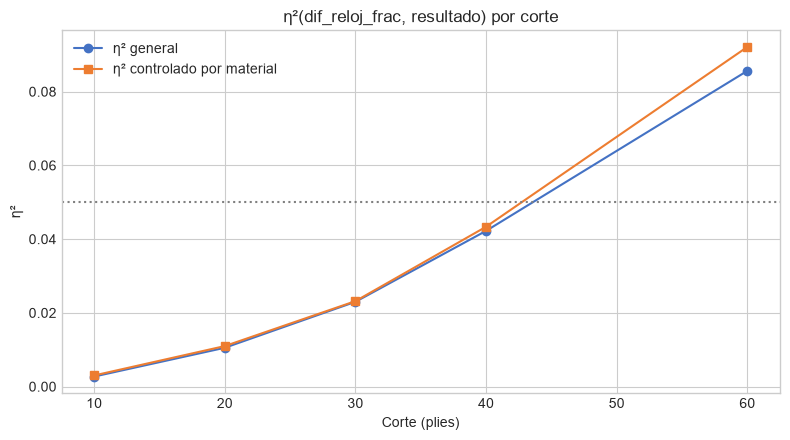

In [11]:
common["banda_material"] = pd.cut(common["balance_material"], bins=[-np.inf, -3, -1, 1, 3, np.inf],
                                   labels=["≤ -4", "-3 a -2", "-1 a 1", "2 a 3", "≥ 4"])
h2 = eta2_por_corte(common, "dif_reloj_frac")
h2_controlado = pd.Series({
    k: eta2_controlado(g, "dif_reloj_frac", "resultado", "banda_material") for k, g in common.groupby("corte_ply")
})
h2_tabla = pd.DataFrame({"eta2": h2, "eta2_controlado": h2_controlado})
h2_tabla["zona"] = [ZONA_EMOJI[semaforo(v, "eta2")] for v in h2_tabla["eta2"]]
h2_tabla["zona_controlado"] = [ZONA_EMOJI[semaforo(v, "eta2")] for v in h2_tabla["eta2_controlado"]]
display(h2_tabla)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(h2.index, h2.values, marker="o", label="η² general", color="#4472c4")
ax.plot(h2_controlado.index, h2_controlado.values, marker="s", label="η² controlado por material", color="#ed7d31")
ax.axhline(0.05, color="gray", linestyle=":")
ax.set(title="η²(dif_reloj_frac, resultado) por corte", xlabel="Corte (plies)", ylabel="η²")
ax.legend()
plt.tight_layout()
plt.show()

**Movimiento (1 de 2 permitidos, H2′ quedó en 🟡 en el ply 60).** Se parte por ritmo, elegido porque en bullet el tiempo base es mínimo y la diferencia de reloj debería pesar más que en rapid. Se reportan los tres ritmos y el general.

In [12]:
h2_ritmo = pd.DataFrame({
    ritmo: {k: eta2(g["dif_reloj_frac"], g["resultado"]) for k, g in sub.groupby("corte_ply")}
    for ritmo, sub in common.groupby("TimeClass", observed=True)
})[TIME_ORDER]
h2_ritmo["general"] = h2
display(h2_ritmo)
print("Partidas por ritmo en la población común:")
display(common[common["corte_ply"] == max_cut]["TimeClass"].value_counts().reindex(TIME_ORDER))

,bullet,blitz,rapid,general
10,0.008,0.001,0.002,0.003
20,0.022,0.008,0.003,0.011
30,0.041,0.021,0.008,0.023
40,0.070,0.041,0.011,0.042
60,0.145,0.087,0.021,0.086


Partidas por ritmo en la población común:


TimeClass
bullet    14447
blitz     29632
rapid      7187
Name: count, dtype: int64

**Resultado:** η² = 0,003 · 0,011 · 0,023 · 0,042 · 0,086 por corte; controlado por material: 0,003 · 0,011 · 0,023 · 0,043 · 0,092. Por ritmo, en el ply 60: bullet 0,145 · blitz 0,087 · rapid 0,021. El control casi no mueve el valor: la ventaja de reloj no repite la información del material. Con el movimiento, el orden bullet > blitz > rapid se cumple en los cortes 20, 30, 40 y 60.

**Zona:** 🔴 hasta el ply 40 y 🟡 en el 60, con y sin control; por ritmo, bullet 🟡, blitz 🟡 y rapid 🔴 en el ply 60.

**Decisión: entra al modelo, y modulada por el ritmo.** No es una relación fuerte (ninguna zona llega a 🟢), pero aporta señal propia que no es un eco del material, y pesa en los ritmos rápidos y casi nada en rapid. Junto con H1′: el reloj pesa en bullet y el material en rapid, así que conviene dejar `TimeClass` como variable que module a las dos.


## 7 · H3′ — Estado de la partida y plies restantes (*Predecir*, objetivo secundario)

| Campo | Contenido |
|---|---|
| **Afirmación** | Cuanto menos material sin peones queda (`material_no_peon_frac`) y menos reloj tiene el jugador con menos tiempo (`reloj_min_frac`), menos plies faltan para el final. Decide si esas columnas entran al modelo de duración. |
| **Qué espero ver** | Correlación positiva (Spearman) de ambas variables con `plies_restantes`. |
| **Medida y gráfico** | Asociación: `asociacion(variable, plies_restantes)` dentro de cada corte (así no se mezcla el avance de la partida con la variable). Pearson, Spearman y brecha, sobre la población común. |

In [13]:
filas = []
for k, g in common.groupby("corte_ply"):
    for variable in ["material_no_peon_frac", "reloj_min_frac"]:
        r = asociacion(g[variable], g["plies_restantes"])
        filas.append({"corte_ply": k, "variable": variable, **r.to_dict()})
h3 = pd.DataFrame(filas).set_index(["corte_ply", "variable"])
h3["zona_spearman"] = [ZONA_EMOJI[semaforo(v, "correlacion")] for v in h3["spearman"]]
display(h3)

pearson  spearman  brecha zona_spearman
corte_ply variable                                                      
10        material_no_peon_frac   -0.017    -0.007   0.011             🔴
          reloj_min_frac           0.053     0.054   0.001             🔴
20        material_no_peon_frac   -0.045    -0.032   0.013             🔴
          reloj_min_frac           0.096     0.097   0.001             🔴
30        material_no_peon_frac   -0.074    -0.068   0.006             🔴
          reloj_min_frac           0.123     0.130   0.006             🔴
40        material_no_peon_frac   -0.098    -0.098  -0.001             🔴
          reloj_min_frac           0.155     0.161   0.006             🔴
60        material_no_peon_frac   -0.134    -0.155  -0.022             🔴
          reloj_min_frac           0.224     0.241   0.017             🟡

**Movimiento (1 de 2 permitidos).** Dos zonas distintas en el ply 60: el material salió con signo contrario y el reloj quedó amarillo. Se prueba UNA partición, elegida antes de ver el resultado: el ritmo. Es el candidato natural porque el ritmo cambia cuánto dura una partida y cuánto pesa el reloj, y podría explicar el signo del material como un efecto de composición (la mezcla de ritmos).

In [14]:
at_last = common[common["corte_ply"] == max_cut]
filas = []
for ritmo, sub in at_last.groupby("TimeClass", observed=True):
    for variable in ["material_no_peon_frac", "reloj_min_frac"]:
        r = asociacion(sub[variable], sub["plies_restantes"])
        filas.append({"ritmo": ritmo, "variable": variable, "n": len(sub), **r.to_dict()})
h3_ritmo = pd.DataFrame(filas).set_index(["ritmo", "variable"])
h3_ritmo["zona_spearman"] = [ZONA_EMOJI[semaforo(v, "correlacion")] for v in h3_ritmo["spearman"]]
display(h3_ritmo)

n  pearson  spearman  brecha zona_spearman
ritmo  variable                                                             
bullet material_no_peon_frac  14447   -0.146    -0.169  -0.023             🔴
       reloj_min_frac         14447    0.440     0.453   0.013             🟡
blitz  material_no_peon_frac  29632   -0.140    -0.157  -0.017             🔴
       reloj_min_frac         29632    0.186     0.197   0.011             🔴
rapid  material_no_peon_frac   7187   -0.125    -0.161  -0.036             🔴
       reloj_min_frac          7187    0.137     0.130  -0.007             🔴

**Resultado en el ply 60:** `material_no_peon_frac` Spearman = −0,155 (general) y −0,169 · −0,157 · −0,161 en bullet · blitz · rapid; `reloj_min_frac` Spearman = 0,241 (general) y 0,453 · 0,197 · 0,130 en bullet · blitz · rapid.

**Zona:** material 🔴 en los tres ritmos, con el signo contrario al esperado; reloj 🟡 en bullet y 🔴 en blitz (0,197, justo debajo del corte de 0,20) y en rapid.

**Decisión: refutada para el material, y el reloj depende del ritmo.** El signo negativo del material **no es un efecto de composición**: se mantiene igual de negativo dentro de cada ritmo, así que separar por ritmo no lo explica. Una lectura plausible, no verificada, es de ajedrez: las posiciones con poco material (finales) tienden a durar más que las posiciones con muchas piezas, que se resuelven por táctica; la afirmación original tenía el signo al revés. El reloj en cambio predice la duración sobre todo en bullet (0,453, el valor más alto y aún 🟡), cuando el tiempo es el que termina la partida, y poco en blitz y rapid. `reloj_min_frac` entra para la duración sólo con interacción con `TimeClass`.


## 8 · H4′ — Ventaja del color de las piezas (*Responder*)

| Campo | Contenido |
|---|---|
| **Afirmación** | Las blancas están sobrerrepresentadas en las victorias: `Gana Blancas` supera a `Gana Negras` por más que el azar, y esa ventaja del color cambia con el ritmo. |
| **Qué espero ver** | Una brecha positiva (blancas − negras) de unos pocos puntos porcentuales, con intervalo que no incluye 0, y que no sea igual en bullet, blitz y rapid. |
| **Medida y gráfico** | Composición: proporción de `Gana Blancas` y de `Gana Negras` por ritmo contra la global, con la brecha en puntos porcentuales y su intervalo del 95 %. De apoyo, `eta2` del indicador "ganan blancas" por ritmo para ubicar el tamaño del efecto en el semáforo. Gráfico de barras de la brecha por ritmo. Es una propiedad de la partida completa, no del corte: se calcula sobre el tidy. |

,partidas,blancas_pct,negras_pct,brecha_pp,ic95_pp
TimeClass,,,,,
bullet,"21,916.000",49.361,45.966,3.395,1.292
blitz,"45,461.000",48.826,44.229,4.597,0.886
rapid,"13,320.000",48.986,45.578,3.408,1.650
global,"80,697.000",48.998,44.924,4.075,0.668


η²(ganan blancas, TimeClass) = 0.0000 — zona 🔴


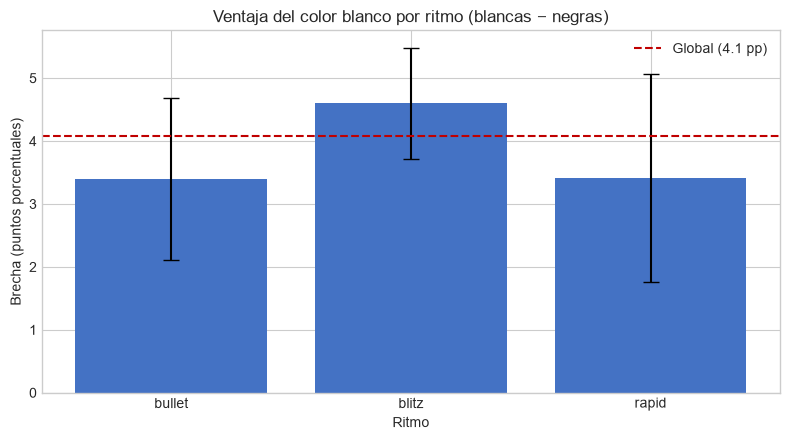

In [15]:
win = games.assign(blancas=(games["resultado"] == "Gana Blancas"), negras=(games["resultado"] == "Gana Negras"))


def brecha_color(frame):
    """White-minus-black share of wins in percentage points, with a 95 % interval."""
    n, pb, pn = len(frame), frame["blancas"].mean(), frame["negras"].mean()
    se = np.sqrt((pb * (1 - pb) + pn * (1 - pn) + 2 * pb * pn) / n)  # variance of a difference of multinomial shares
    return pd.Series({"partidas": n, "blancas_pct": pb * 100, "negras_pct": pn * 100,
                      "brecha_pp": (pb - pn) * 100, "ic95_pp": 1.96 * se * 100})


h4_global = brecha_color(win)
h4_ritmo = win.groupby("TimeClass", observed=True).apply(brecha_color, include_groups=False).reindex(TIME_ORDER)
h4_ritmo.loc["global"] = h4_global
display(h4_ritmo)
h4_eta = eta2(win["blancas"].astype(float), win["TimeClass"])
print(f"η²(ganan blancas, TimeClass) = {h4_eta:.4f} — zona {ZONA_EMOJI[semaforo(h4_eta, 'eta2')]}")

fig, ax = plt.subplots(figsize=(8, 4.5))
plot = h4_ritmo.loc[TIME_ORDER]
ax.bar(plot.index, plot["brecha_pp"], yerr=plot["ic95_pp"], color="#4472c4", capsize=6)
ax.axhline(h4_global["brecha_pp"], color="#c00000", linestyle="--", label=f"Global ({h4_global['brecha_pp']:.1f} pp)")
ax.set(title="Ventaja del color blanco por ritmo (blancas − negras)", xlabel="Ritmo", ylabel="Brecha (puntos porcentuales)")
ax.legend()
plt.tight_layout()
plt.show()

**Movimiento (1 de 2 permitidos).** Se parte por nivel de los jugadores (`nivel_promedio`), elegido porque la ventaja de mover primero suele ser mayor entre jugadores fuertes, donde hay menos errores que la compensen. Se reportan las cinco bandas.

In [16]:
level_order = ["principiante", "intermedio", "avanzado", "experto", "top_mundial"]
h4_nivel = win.groupby("nivel_promedio", observed=True).apply(brecha_color, include_groups=False).reindex(level_order)
display(h4_nivel)

,partidas,blancas_pct,negras_pct,brecha_pp,ic95_pp
nivel_promedio,,,,,
principiante,"17,027.000",49.216,46.344,2.872,1.468
intermedio,"17,576.000",48.913,46.313,2.600,1.442
avanzado,"14,850.000",49.279,45.623,3.657,1.566
experto,"15,494.000",48.858,44.327,4.531,1.518
top_mundial,"15,750.000",48.730,41.765,6.965,1.482


**Resultado:** brecha global blancas − negras = **4,1 puntos porcentuales** (49,0 % contra 44,9 %, IC 95 % ±0,7). Por ritmo: bullet 3,4 pp (±1,3) · blitz 4,6 pp (±0,9) · rapid 3,4 pp (±1,7). Con el movimiento por nivel: principiante 2,9 · intermedio 2,6 · avanzado 3,7 · experto 4,5 · **top_mundial 7,0 pp** (±1,5).

**Zona:** η²(ganan blancas, `TimeClass`) = 0,000 → 🔴. El ritmo no explica nada de la ventaja del color.

**Decisión: confirmada la ventaja, refutada la parte "cambia con el ritmo".** La ventaja de mover primero existe y su intervalo no incluye 0, pero es la misma en los tres ritmos (los intervalos se solapan). Lo que sí cambia es el nivel: en `top_mundial` la brecha es la más alta (7,0 pp contra 2,6–4,5 en las otras bandas) y su intervalo no se solapa con los de principiante, intermedio ni avanzado, con Empate más alto (9,5 %). Para el modelo, esta ventaja no es una columna: `resultado` ya está expresado como Blancas/Negras, así que el color queda absorbido en las frecuencias base (el piso M0 del notebook 03).


### Resumen de las cuatro hipótesis

Una fila por hipótesis, con la pregunta que responde, la medida, la zona y la decisión final. Los números se calculan acá, no se copian.

In [17]:
resumen = pd.DataFrame([
    {"hipotesis": "H1′ · Material y resultado", "pregunta": "Responder (dominio)",
     "medida": f"η² ply 60 = {h1.loc[60]:.3f} (rapid {h1_ritmo.loc[60, 'rapid']:.3f})",
     "zona": ZONA_EMOJI[semaforo(h1.loc[60], "eta2")], "decision": "Parcialmente confirmada: señal amarilla y tardía"},
    {"hipotesis": "H2′ · Reloj sobre el material", "pregunta": "Predecir (columna del modelo)",
     "medida": f"η² ply 60 = {h2.loc[60]:.3f}; controlado = {h2_controlado.loc[60]:.3f}; bullet {h2_ritmo.loc[60, 'bullet']:.3f} · rapid {h2_ritmo.loc[60, 'rapid']:.3f}",
     "zona": ZONA_EMOJI[semaforo(h2_controlado.loc[60], "eta2")], "decision": "Entra, modulada por el ritmo: aporta señal propia, no repite el material"},
    {"hipotesis": "H3′ · Estado y plies restantes", "pregunta": "Predecir (columna del modelo; objetivo secundario)",
     "medida": f"Spearman ply 60: material = {h3.loc[(60, 'material_no_peon_frac'), 'spearman']:.3f}; reloj = {h3.loc[(60, 'reloj_min_frac'), 'spearman']:.3f} (bullet {h3_ritmo.loc[('bullet', 'reloj_min_frac'), 'spearman']:.3f})",
     "zona": ZONA_EMOJI[semaforo(h3.loc[(60, 'reloj_min_frac'), 'spearman'], "correlacion")], "decision": "Refutada para material (signo contrario, robusto al ritmo); reloj depende del ritmo"},
    {"hipotesis": "H4′ · Ventaja del color", "pregunta": "Responder (dominio)",
     "medida": f"Brecha blancas − negras = {h4_global['brecha_pp']:.1f} pp (IC ±{h4_global['ic95_pp']:.1f}); η² por ritmo = {h4_eta:.4f}",
     "zona": ZONA_EMOJI[semaforo(h4_eta, "eta2")], "decision": "Ventaja confirmada (no cambia con el ritmo); es la más alta en top_mundial"},
]).set_index("hipotesis")
display(resumen)

,pregunta,medida,zona,decision
hipotesis,,,,
H1′ · Material y resultado,Responder (dominio),η² ply 60 = 0.118 (rapid 0.205),🟡,Parcialmente confirmada: señal amarilla y tardía
H2′ · Reloj sobre el material,Predecir (columna del modelo),η² ply 60 = 0.086; controlado = 0.092; bullet ...,🟡,"Entra, modulada por el ritmo: aporta señal pro..."
H3′ · Estado y plies restantes,Predecir (columna del modelo; objetivo secunda...,Spearman ply 60: material = -0.155; reloj = 0....,🟡,"Refutada para material (signo contrario, robus..."
H4′ · Ventaja del color,Responder (dominio),Brecha blancas − negras = 4.1 pp (IC ±0.7); η²...,🔴,Ventaja confirmada (no cambia con el ritmo); e...


## 9 · Columnas candidatas y control de fuga

Es la tabla que se lleva el modelado. Una fila por columna que se piensa darle al modelo. La última columna es el chequeo de fuga: **¿existiría esa columna en el momento de predecir?** Si la respuesta ya está adentro, no es una feature, es la respuesta escrita de otra forma.

Para las columnas que existen en vivo, la zona sale del η² contra `resultado` en el ply 60 sobre la población común. Para el rating de Chess.com el η² se calcula sobre todas las partidas del tidy (no hay corte): se muestra igual, porque una variable con η² alto y fuga es justo el caso a documentar.

In [18]:
at_60 = common[common["corte_ply"] == max_cut]
candidates = {
    "balance_material": "Puntos de material de blancas − negras en el corte",
    "material_no_peon_frac": "Material sin peones, fracción del máximo (62 pts)",
    "dif_reloj_frac": "Reloj de blancas − negras, fracción del tiempo base",
    "reloj_min_frac": "Menor reloj de los dos, fracción del tiempo base",
    "movilidad": "Cantidad de jugadas legales en la posición",
    "en_jaque": "El bando que mueve está en jaque",
    "capturas_blancas": "Capturas acumuladas de blancas",
    "capturas_negras": "Capturas acumuladas de negras",
    "jaques_blancas": "Jaques dados por blancas hasta el corte",
    "jaques_negras": "Jaques dados por negras hasta el corte",
    "enroco_blancas": "Blancas ya enrocaron",
    "enroco_negras": "Negras ya enrocaron",
    "promociones": "Coronaciones hasta el corte",
}
rows = []
for column, mide in candidates.items():
    value = eta2(at_60[column].astype(float), at_60["resultado"])
    zone = semaforo(value, "eta2")
    share_nonzero = (at_60[column].astype(float) != 0).mean()
    if share_nonzero < 0.02:
        decision = f"Sale: casi constante (distinta de 0 en el {share_nonzero * 100:.1f} % de las filas)"
    elif column == "reloj_min_frac":
        decision = "Entra sólo para duración (plies_restantes): casi no separa el resultado"
    elif zone == "rojo":
        decision = "A evaluar con importancia por permutación en el notebook 03 (señal débil sola)"
    else:
        decision = "Entra"
    rows.append({"columna": column, "mide": mide, "eta2": value, "zona": ZONA_EMOJI[zone],
                 "decision": decision, "existe_al_predecir": "Sí — se observa en el corte"})

rows.append({"columna": "turno_blancas", "mide": "Bando que mueve en el corte", "eta2": np.nan, "zona": "—",
             "decision": "Sale: constante (todos los cortes, incluido el 0, son plies pares: mueven blancas)",
             "existe_al_predecir": "Sí, pero no informa"})
leak_eta = eta2(games["diferencia_elo"], games["resultado"])
rows += [
    {"columna": "diferencia_elo / WhiteElo / BlackElo", "mide": "Rating de Chess.com, posterior a la partida",
     "eta2": leak_eta, "zona": ZONA_EMOJI[semaforo(leak_eta, "eta2")], "decision": "Sale",
     "existe_al_predecir": "No — se actualiza al terminar la partida; el signo del cambio coincide con el resultado en el 99,91 % (notebook 02)"},
    {"columna": "Termination", "mide": "Cómo terminó la partida", "eta2": np.nan, "zona": "—", "decision": "Sale",
     "existe_al_predecir": "No — se completa al terminar"},
    {"columna": "cantidad_jugadas", "mide": "Plies totales de la partida", "eta2": np.nan, "zona": "—", "decision": "Sale",
     "existe_al_predecir": "No — con el corte da plies_restantes exacto, es el objetivo escrito de otra forma"},
    {"columna": "ECO / Opening / familia_apertura", "mide": "Apertura asignada por Chess.com", "eta2": np.nan, "zona": "—", "decision": "Sale",
     "existe_al_predecir": "No — se asigna mirando la línea completa (hasta 40 plies): en cortes tempranos revela jugadas futuras"},
    {"columna": "TimeClass / tiempo_base_seg / incremento_seg", "mide": "Ritmo y control de tiempo", "eta2": np.nan, "zona": "—",
     "decision": "Entra (contexto; módula reloj y material)", "existe_al_predecir": "Sí — se conoce antes de empezar"},
    {"columna": "matchup_apertura y tasas históricas", "mide": "Primera jugada de blancas × respuesta de negras y su historial previo",
     "eta2": np.nan, "zona": "—", "decision": "Probada y descartada (ablación en el notebook 03: ±0,004 de log-loss)",
     "existe_al_predecir": "Desde el ply 2 — usa sólo los plies 1 y 2, e historial con partidas terminadas antes del inicio"},
    {"columna": "EsTorneo", "mide": "La partida es de un torneo", "eta2": np.nan, "zona": "—",
     "decision": "Entra (contexto)", "existe_al_predecir": "Sí — se conoce antes de empezar"},
    {"columna": "elo_blancas_previo / elo_negras_previo", "mide": "Rating previo reconstruido (src/rating_history.py)",
     "eta2": np.nan, "zona": "—", "decision": "Entra (notebook 03); sólo se conoce un lado, el otro queda NaN",
     "existe_al_predecir": "Sí — es el rating al cierre de la partida anterior del mismo ritmo"},
]
candidatas = pd.DataFrame(rows).set_index("columna")
display(candidatas)
assert candidatas.index.is_unique

,mide,eta2,zona,decision,existe_al_predecir
columna,,,,,
balance_material,Puntos de material de blancas − negras en el c...,0.118,🟡,Entra,Sí — se observa en el corte
material_no_peon_frac,"Material sin peones, fracción del máximo (62 pts)",0.010,🔴,A evaluar con importancia por permutación en e...,Sí — se observa en el corte
dif_reloj_frac,"Reloj de blancas − negras, fracción del tiempo...",0.086,🟡,Entra,Sí — se observa en el corte
reloj_min_frac,"Menor reloj de los dos, fracción del tiempo base",0.008,🔴,Entra sólo para duración (plies_restantes): ca...,Sí — se observa en el corte
movilidad,Cantidad de jugadas legales en la posición,0.035,🔴,A evaluar con importancia por permutación en e...,Sí — se observa en el corte
en_jaque,El bando que mueve está en jaque,0.007,🔴,A evaluar con importancia por permutación en e...,Sí — se observa en el corte
capturas_blancas,Capturas acumuladas de blancas,0.021,🔴,A evaluar con importancia por permutación en e...,Sí — se observa en el corte
capturas_negras,Capturas acumuladas de negras,0.022,🔴,A evaluar con importancia por permutación en e...,Sí — se observa en el corte
jaques_blancas,Jaques dados por blancas hasta el corte,0.009,🔴,A evaluar con importancia por permutación en e...,Sí — se observa en el corte


**Lectura.**

- **Entran por señal propia:** `balance_material` (η² 0,118) y `dif_reloj_frac` (0,086), las dos amarillas en el ply 60.
- **Señal débil sola, a evaluar en el modelo:** movilidad, capturas, jaques y `material_no_peon_frac`. Un η² bajo sólo dice que la variable aislada separa poco; el aporte conjunto lo mide el notebook 03.
- **Salen por constantes o casi constantes:** `turno_blancas` y `promociones`.
- **Salen por fuga:** el rating de Chess.com (posterior a la partida), `Termination` y `cantidad_jugadas` (revelan el final), y `ECO`/`Opening`/`familia_apertura` (se asignan mirando la línea completa). El rating llega a η² = 0,091, casi igual que el material en el ply 60, y es el caso a recordar: da una asociación parecida y no existe al predecir. Su reemplazo sin fuga es el rating previo reconstruido.
- **`reloj_min_frac`** casi no separa el resultado (0,008) porque es simétrica entre blancas y negras; sólo entra para la duración (H3′).


## 10 · Conclusiones para el modelado

- **La señal aparece tarde.** Ninguna variable sola sale de la zona roja antes del ply 40 y ninguna llega a verde en el ply 60. Es coherente con el notebook 03: sobre la población común el modelo en vivo empata con el piso hasta el ply 20 y lo supera desde el 30.
- **Material y reloj son señales distintas.** El control por material no baja el η² del reloj (H2′), y los ritmos los ordenan al revés (H1′ y H2′). Conviene dejar los dos grupos de variables y permitir interacción con `TimeClass`.
- **El material sin peones no predice la duración como se esperaba** (H3′): el signo contrario se mantiene dentro de cada ritmo, así que no es un efecto de mezcla de ritmos. El reloj sí predice la duración en bullet.
- **Inconcluso.** Qué pasa en cortes posteriores al ply 60 (la mediana de duración es de 71 plies): haría falta agregar cortes 80 y 100 a `live_prediction.cortes_ply` y regenerar, con una población común más chica.
- **Limitación.** Los η² son bivariados y sobre la población común (partidas que llegan al ply 60); no miden el aporte conjunto ni la generalización a jugadores nuevos. Eso lo mide el notebook 03. El rating previo no se evalúa acá: sólo existe para la cuenta seleccionada y el del rival casi siempre falta.


## 11 · Verificación

Se comprueba que las cifras salen de datos íntegros: clave única, sin nulos en las columnas usadas, η² dentro de [0, 1] y los cinco cortes con jugadas presentes para cada partida de la población común.

In [19]:
USED = ["balance_material", "dif_reloj_frac", "material_no_peon_frac", "reloj_min_frac", "plies_restantes", "resultado"]
assert not data.duplicated(["GameUrl", "corte_ply"]).any(), "Clave (GameUrl, corte_ply) repetida"
assert common[USED].notna().all().all(), "Nulos en columnas usadas"
assert ((h1 >= 0) & (h1 <= 1)).all() and ((h2 >= 0) & (h2 <= 1)).all()
assert set(common["corte_ply"].unique()) == set(LIVE_CUTS)
assert set(common["resultado"].unique()) <= set(RESULT_ORDER)
assert (cuts["plies_restantes"] > 0).all()
print("Verificación OK:", f"{len(common_urls):,} partidas × {len(LIVE_CUTS)} cortes, sin nulos en las columnas usadas")

Verificación OK: 51,266 partidas × 5 cortes, sin nulos en las columnas usadas
